## Verification of post processing

In this file I compare the raw tracks from Priestly to the filtered tracks.
The goal is to verify that the postprocessing method keeps the correct tracks.

# Workflow
1. Load raw and filtered tracks
2. Clip to all tracks to domain and update the track-ids
3. Convert both datasets to TRACK objects
4. Run postprocessing algorithm objects
5. validate by comparing the filtered objects of both sets
6. As fraction of overlap is 1.0 and mean_sep_km is 0.0 i can conclude that the tracks are identical. 
7. This means that my postprocessing filter keeps the same tracks as Preistly in the chosen domain when used on raw tracks

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import statistics_on_tracks as sot
from configs import *

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel
importlib.reload(sot)  # pick up edits in statistic_on_tracks.py without restarting the kernel

import importlib

In [2]:
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks
df_all = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_ALL_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
df_all=df_all.rename(columns={'vorticity': 'vo'})

In [3]:
df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
df_validation=df_validation.rename(columns={'vorticity': 'vo'})

In [4]:
df_validation = val.clip_to_domain(df_validation, DOMAIN, TIME_RANGE)
df_all = val.clip_to_domain(df_all, DOMAIN, TIME_RANGE)

In [5]:
tracks_validation = val.dataframe_to_tracks(df_validation, variable = 'vo', scale=1e-5)  # convert to s^-1
tracks_all = val.dataframe_to_tracks(df_all, variable = 'vo', scale=1e-5)  # convert to s^-1

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


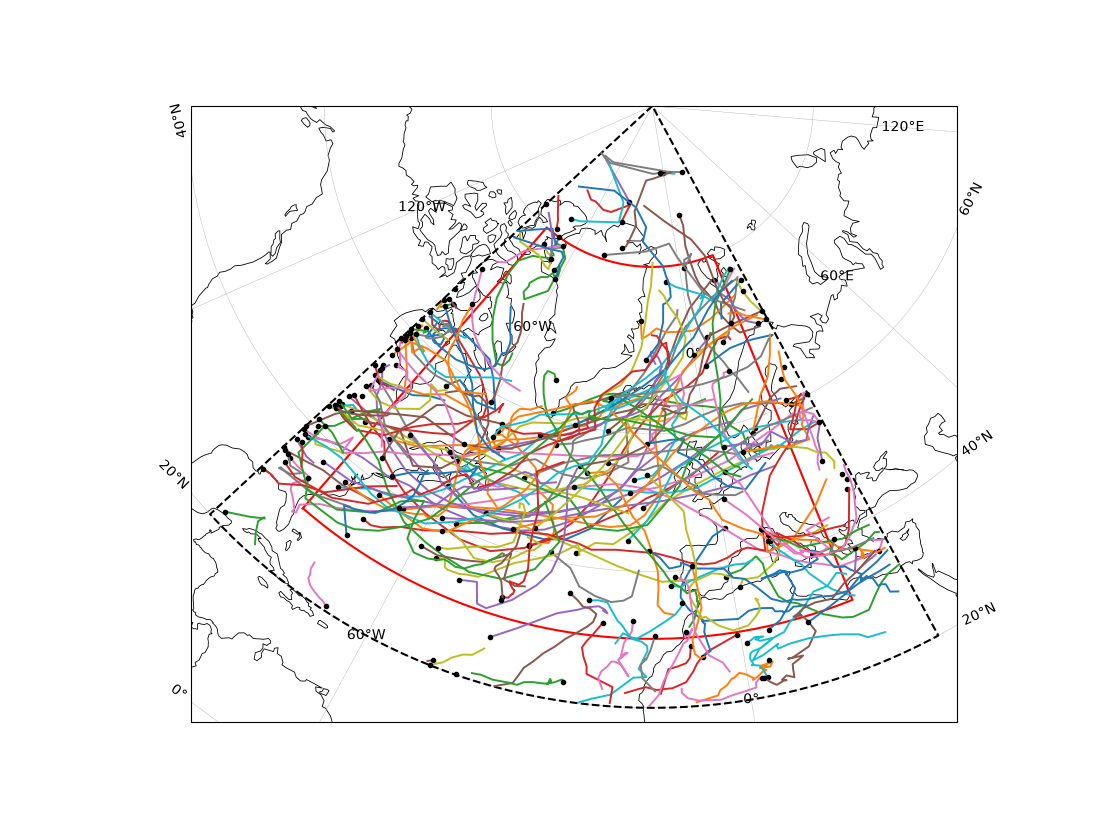

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


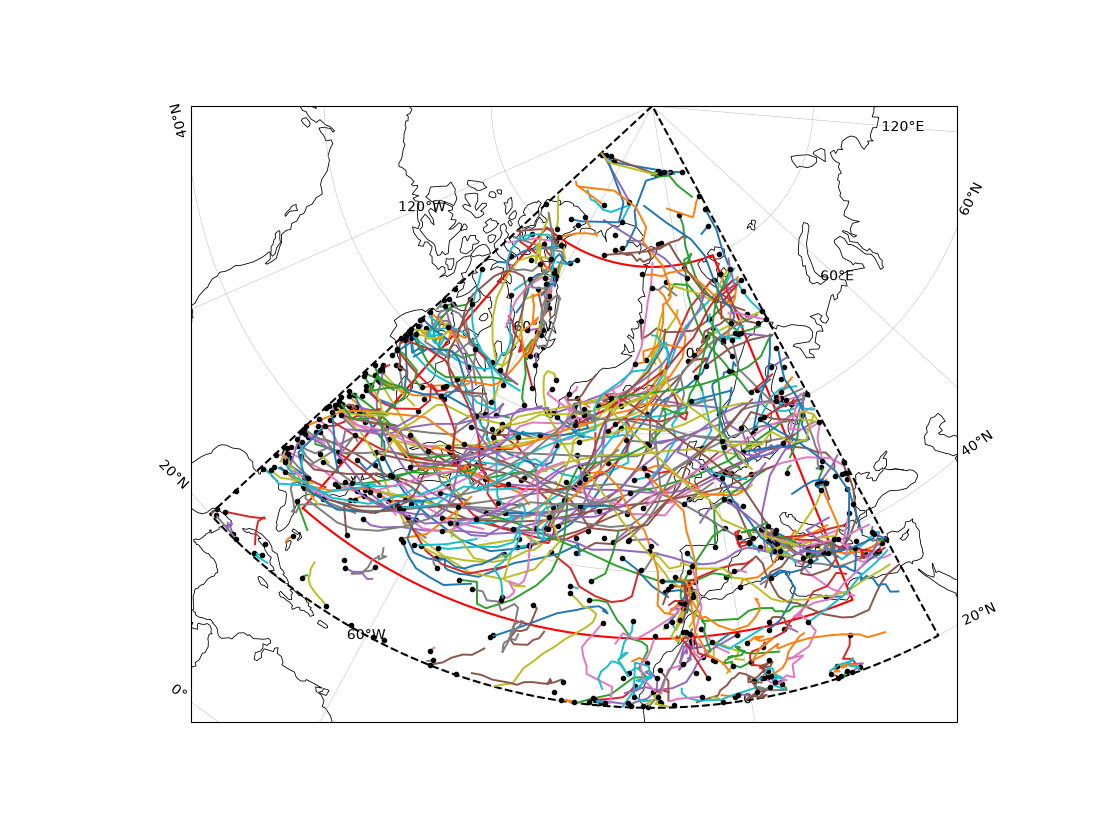

In [6]:
ax = val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN) 
plt.show()
ax = val.plot_regional_tracks(tracks_all, region=REGION, domain=DOMAIN)

In [7]:
tracks_validation, summary_validation, points_validation = pro.postprocess_tracks(tracks_validation, **POSTPROCESS_CONFIG)

tracks_all, summary_all, points_all = pro.postprocess_tracks(tracks_all, **POSTPROCESS_CONFIG)

In [8]:
report_validation = pro.filter_report(summary_validation)
report_all = pro.filter_report(summary_all)

raw tracks: 208, kept: 114
raw tracks: 602, kept: 114


In [9]:
print("Validation tracks report:")
print(report_validation)
print("\nAll tracks report:")
print(report_all)

Validation tracks report:
         removed_by_this_criterion  removed_only_by_this_criterion
rsplice                         82                              31
region                          32                               0
edge                            38                              12
peak                             0                               0
time                             0                               0

All tracks report:
         removed_by_this_criterion  removed_only_by_this_criterion
rsplice                        476                             294
region                          78                               0
edge                           137                              12
peak                             0                               0
time                             0                               0


In [10]:
comparison, matches_df = val.compare_to_validation(tracks_validation, tracks_all, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [11]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,300,300,1.0,8,0.000012,0.000095,8,8,0.000046,0.000046,1,0.0,0.0
1,700,700,1.0,23,0.000010,0.000134,23,23,0.000116,0.000116,1,0.0,0.0
2,800,800,1.0,28,0.000010,0.000095,28,28,0.000061,0.000061,1,0.0,0.0
3,1100,1100,1.0,20,0.000009,0.000095,20,20,0.000073,0.000073,1,0.0,0.0
4,5300,5300,1.0,14,0.000014,0.000095,14,14,0.000032,0.000032,1,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,244700,244700,1.0,21,0.000026,0.000134,21,21,0.000056,0.000056,1,0.0,0.0
110,246100,246100,1.0,11,0.000000,0.000000,11,11,0.000108,0.000108,1,0.0,0.0
111,252000,252000,1.0,9,0.000025,0.000134,9,9,0.000098,0.000098,1,0.0,0.0
112,252100,252100,1.0,9,0.000032,0.000095,9,9,0.000026,0.000026,1,0.0,0.0


In [12]:
results_df = pd.Series({
    'Number of validation tracks': len(tracks_validation),
    'Number of all tracks': len(tracks_all),
    'Number of matched tracks': comparison.tp,
    'Number of missed tracks': comparison.fn,
    'Number of extra tracks': comparison.fp,
    'F1 score': comparison.f1,
    'Precision': comparison.precision,
    'Recall': comparison.recall,
})  

In [13]:
results_df

Number of validation tracks    114.0
Number of all tracks           114.0
Number of matched tracks       114.0
Number of missed tracks          0.0
Number of extra tracks           0.0
F1 score                         1.0
Precision                        1.0
Recall                           1.0
dtype: float64